# 04 · Unmixing

The CCA-family models look for a weighted sum of the EEG channels and a weighted sum
of the fNIRS channels that rise and fall together. Each such pair of components is a
candidate for a source the two modalities share, such as the activity of one motor
cortex. This notebook builds that up in four steps:

1. **One model by hand**: fit ElasticNetCCA on the training groups and look at its
   pairs
2. **Pairs to hands**: decide which pair belongs to which hand, and score it on the
   held-out test group
3. **Choosing hyperparameters**: leave-one-group-out cross-validation for a method
   with a grid
4. **The whole pipeline**: `run`, which does all of this for every method of the
   experiment and saves the result for notebook 05

A pair is never split: its EEG and its fNIRS component are always assigned, scored
and classified together.

In [1]:
SUBJECT_CONFIG = "configs/subjects/synthetic/sub01/sub01_snr_fnirs-5_eeg5.yaml"
EXPERIMENT_CONFIG = "configs/experiments/tutorial.yaml"

# For your own data, point SUBJECT_CONFIG at its subject config. If its files are in a
# format the pipeline does not read yet, add a loader for it first (notebook 06).

In [2]:
import logging
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_experiment, load_subject
from src.experiment import run
from src.loading import load_backgrounds, load_recordings, select_pruning_recordings
from src.log import setup_logging
from src.preprocessing import preprocess_recordings, split_into_blocks
from src.pruning import prune_recordings
from src.types import Geometry, Selection
from src.unmixing import find_hands, selection_report, split
from src.unmixing.concat import concat_runs
from src.unmixing.fit import fit_model
from src.unmixing.scores import canonical_r, components, score
from src.unmixing.select import select_and_score
from src.visualization import plot_pair_assignment, plot_patterns, plot_time_courses
from src.visualization.style import MODALITY

logger = setup_logging()
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="A worker stopped while some jobs", category=UserWarning)


class RelativePaths(logging.Filter):
    """Write every path inside the project relative to it in the pipeline's log."""

    def filter(self, record):
        record.msg = str(record.msg).replace(f"{PROJECT_ROOT}/", "")
        return True


logger.addFilter(RelativePaths())


def pruned_runs(subject, cfg):
    """The subject's runs after pruning, as main.py prunes them."""
    recordings = load_recordings(subject)
    backgrounds = load_backgrounds(subject)
    references = select_pruning_recordings(subject, recordings, backgrounds)
    return prune_recordings(recordings, references, backgrounds, cfg.pruning)

subject = load_subject(PROJECT_ROOT / SUBJECT_CONFIG)
cfg = load_experiment(PROJECT_ROOT / EXPERIMENT_CONFIG)

The preprocessed runs, as in notebook 03. A session recorded in one piece (Buccino)
is split into its blocks only now, so no filter had an edge at a block boundary.

In [3]:
pruned, _ = pruned_runs(subject, cfg)
recordings = preprocess_recordings(pruned, cfg.preprocessing)
if any(r.blocks is not None for r in recordings):
    recordings = split_into_blocks(recordings, subject.groups)
print(f"{len(recordings)} runs in groups {sorted({r.group for r in recordings})}")

15 runs in groups ['sitting_post_rest_1', 'sitting_post_rest_2', 'sitting_pre_rest_1', 'sitting_pre_rest_2', 'sitting_pre_rest_3']


## 1. One model by hand

The test group is held out; the model is fit on all other groups (the *dev* groups).
`concat_runs` joins each set of runs end to end on one time axis.

In [4]:
dev, test = split(recordings, subject.test_group)
dev_joined, test_joined = concat_runs(dev), concat_runs(test)
print(f"Dev:  {len(dev)} runs, EEG {dict(dev_joined.eeg.sizes)}, fNIRS {dict(dev_joined.fnirs.sizes)}")
print(f"Test: {len(test)} runs of {subject.test_group}")

Dev:  12 runs, EEG {'time': 10798, 'channel': 31}, fNIRS {'time': 10798, 'channel': 104}
Test: 3 runs of sitting_post_rest_1


`fit_model` builds and fits one method from `src/unmixing/models.py` (`METHODS`).

Plain CCA gives every channel a weight. With dozens of channels and noisy data it
easily fits noise that happens to correlate in the training runs. **ElasticNetCCA**
regularises the weights with two penalties, one value per modality (`[EEG, fNIRS]`):

- `l1_reg` pushes most channel weights to exactly zero, so each component draws on a
  few channels, as a local source would
- `l2_reg` shrinks the remaining weights, which keeps the fit stable when neighbouring
  channels are strongly correlated

The values below are the ones leave-one-group-out cross-validation selects from the
full ElasticNetCCA grid in `configs/unmixing/grids.yaml`, using the dev groups only.
Section 3 shows how that selection works.

The model returns as many pairs as the smaller modality has channels, ordered by how
strongly their two components correlate (the *canonical correlation*).

In [5]:
METHOD = "ElasticNetCCA"
PARAMS = {"l1_reg": [0.2, 0.2], "l2_reg": [1.0, 1.5]}    # [EEG, fNIRS]

fitted = fit_model(METHOD, PARAMS, dev_joined, n_components=None, seed=cfg.unmixing.seed)

u_dev, u_dev_paired, v_dev = components(fitted, dev_joined)
u_test, u_test_paired, v_test = components(fitted, test_joined)
n_pairs = v_dev.sizes["component"]
r_dev = [canonical_r(u_dev_paired, v_dev, k) for k in range(n_pairs)]
r_test = [canonical_r(u_test_paired, v_test, k) for k in range(n_pairs)]
print(f"{n_pairs} pairs")

31 pairs


On the data it was fit on, every pair correlates by construction. On the held-out
test group, a pair that only fit noise of the training runs loses its correlation,
while a pair that captures a source the two modalities share keeps it. The penalties
stop the fit from chasing noise, which is also why the training correlations are
modest: the strongest pairs correlate about as well on the test group as on the
training runs.

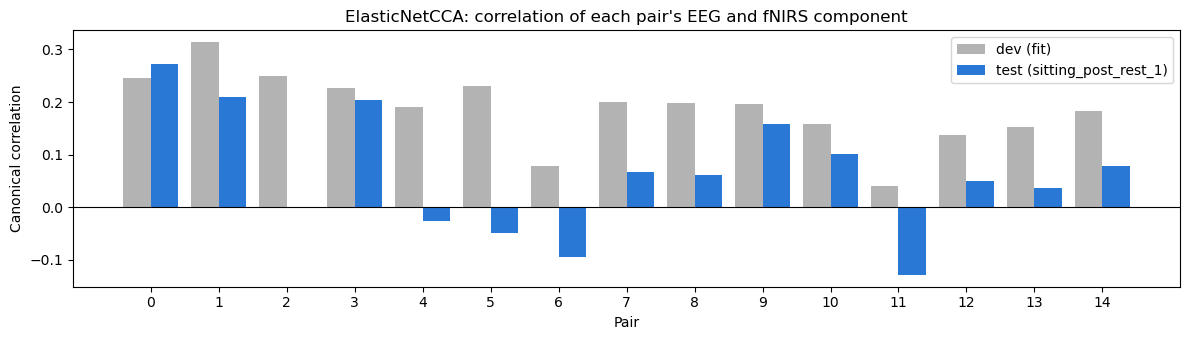

In [6]:
shown = min(n_pairs, 15)
x = np.arange(shown)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(x - 0.2, r_dev[:shown], width=0.4, color="0.7", label="dev (fit)")
ax.bar(x + 0.2, r_test[:shown], width=0.4, color=MODALITY["eeg"], label=f"test ({subject.test_group})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x)
ax.set_xlabel("Pair")
ax.set_ylabel("Canonical correlation")
ax.set_title(f"{METHOD}: correlation of each pair's EEG and fNIRS component")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Pairs to hands

The model does not know which pair belongs to which hand. The experiment's
`assignment` decides, looking at the dev groups only:

- `ground_truth` (synthetic data): the pair that correlates best with each simulated
  source
- `motor_channels`: the pair whose spatial pattern lies most over that hand's motor
  cortex
- `task_regressors`: the pair whose components follow that hand's trials best

Every strategy chooses among the first `n_top` pairs (10 in the tutorial experiment).
A hand's source is often not among the very strongest pairs: with `n_top: 2`, the
left hand's source would be missed here, since it sits in a later pair.

`score` assigns the pairs on the dev groups, then measures them on the test group.
`find_hands` lists the hands that have trials.

In [7]:
hands = find_hands(recordings, subject.trial_classes, cfg.hand)
scores, recovery = score(fitted, dev_joined, test_joined, cfg.unmixing.assignment, hands,
                         trial_classes=subject.trial_classes)

print(f"Hands: {hands}; assignment: {cfg.unmixing.assignment.method!r}")
print(f"Pairs: {scores.labels.pairs}")
print(f"Canonical r on the test group: {', '.join(f'{h} {r:+.2f}' for h, r in scores.canonical_r.items())}")
if scores.best_pairs:
    print("Recovery on the test group, |r| with the ground-truth source:")
    for h in hands:
        print(f"  {h}: EEG {scores.r_eeg[h]:.2f}, fNIRS {scores.r_fnirs[h]:.2f}")
    print(f"ISI (0 = perfectly separated sources): EEG {scores.isi_eeg:.2f}, fNIRS {scores.isi_fnirs:.2f}")

Hands: ['right_hand', 'left_hand']; assignment: 'ground_truth'
Pairs: {'right_hand': 0, 'left_hand': 3}
Canonical r on the test group: right_hand +0.27, left_hand +0.20
Recovery on the test group, |r| with the ground-truth source:
  right_hand: EEG 0.51, fNIRS 0.81
  left_hand: EEG 0.42, fNIRS 0.78
ISI (0 = perfectly separated sources): EEG 0.04, fNIRS 0.04


The pipeline's figures take a `Selection`: one fitted model with its scores. Here it
is built by hand from the model above.

**Time courses**: each hand's pair on the test group, against the ground truth
where there is one.

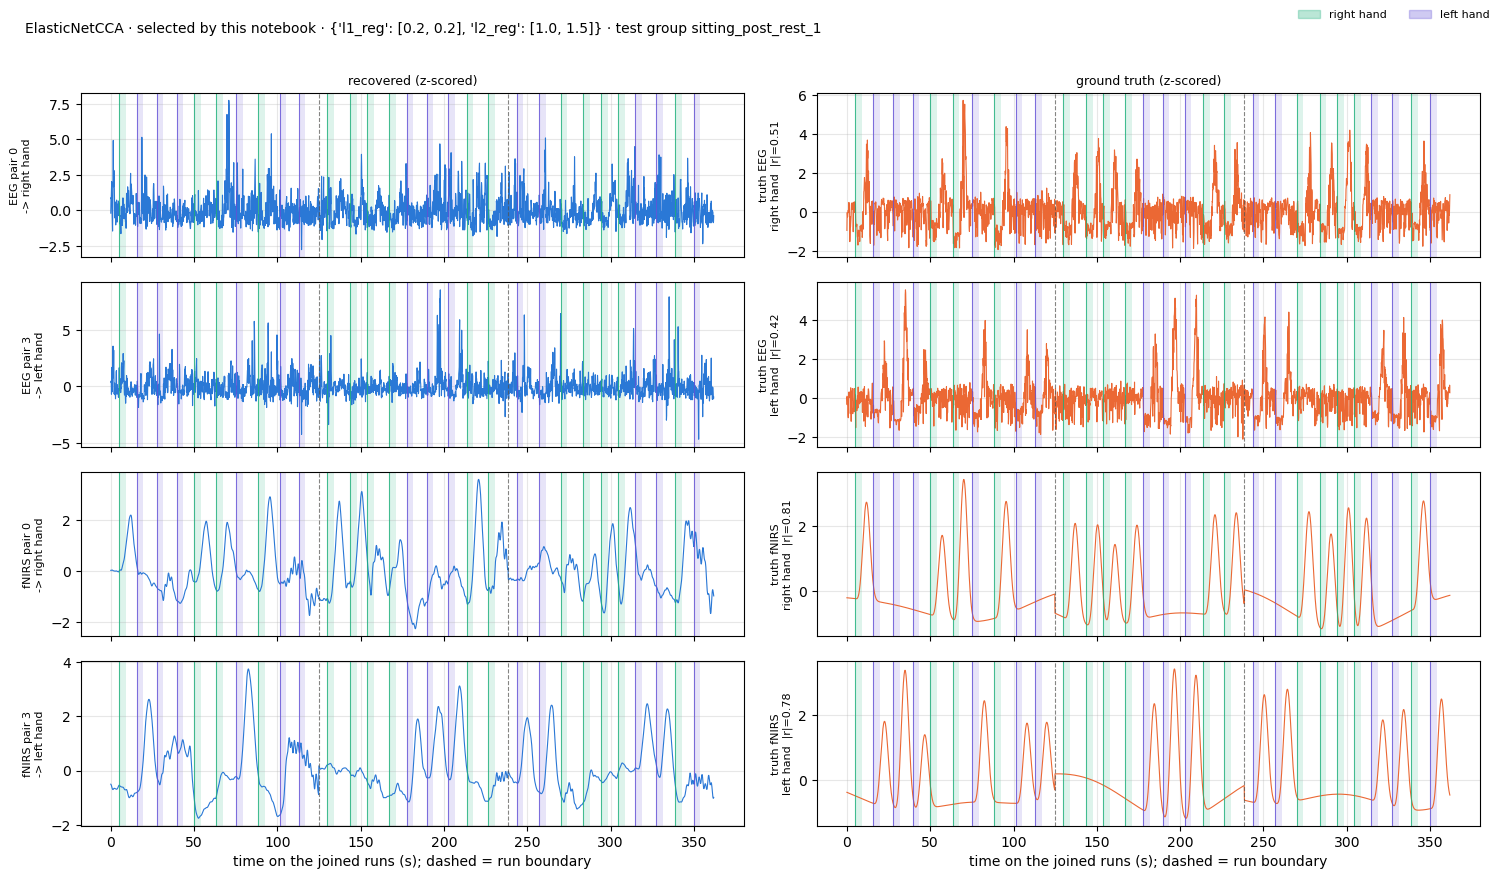

In [8]:
selection = Selection(method=METHOD, metric="this notebook", params=PARAMS, inner_score=np.nan,
                      fitted=fitted, scores=scores, recovery=recovery,
                      test_group=subject.test_group, folds=())
fig = plot_time_courses(selection)
plt.show()

**Spatial patterns**: where on the head each pair's components come from (Haufe
patterns), next to the ground-truth mixing where there is one.

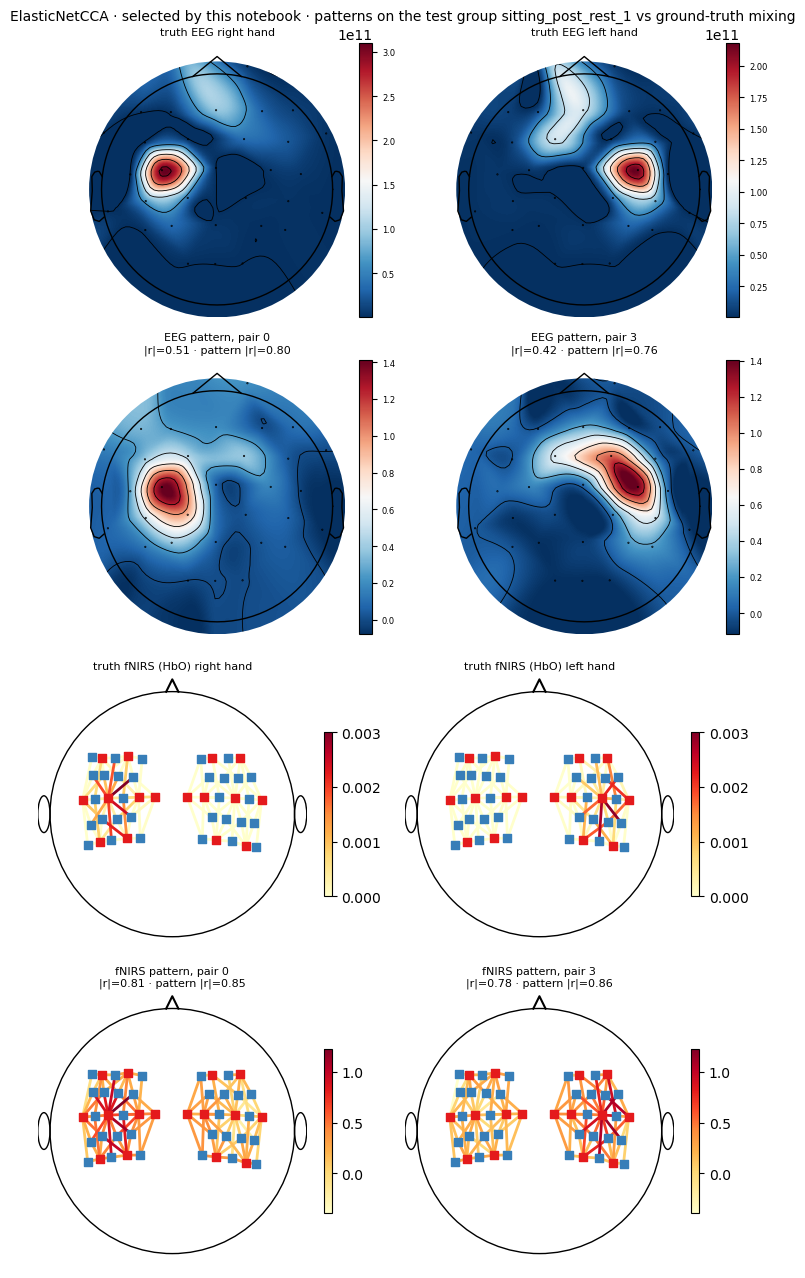

In [9]:
fig = plot_patterns(selection, Geometry.of(recordings[0]),
                    motor_channels=cfg.unmixing.assignment.motor_channels or None)
plt.show()

**Assignment**: how well each of the first pairs matched each hand on the dev groups,
and which pair was chosen.

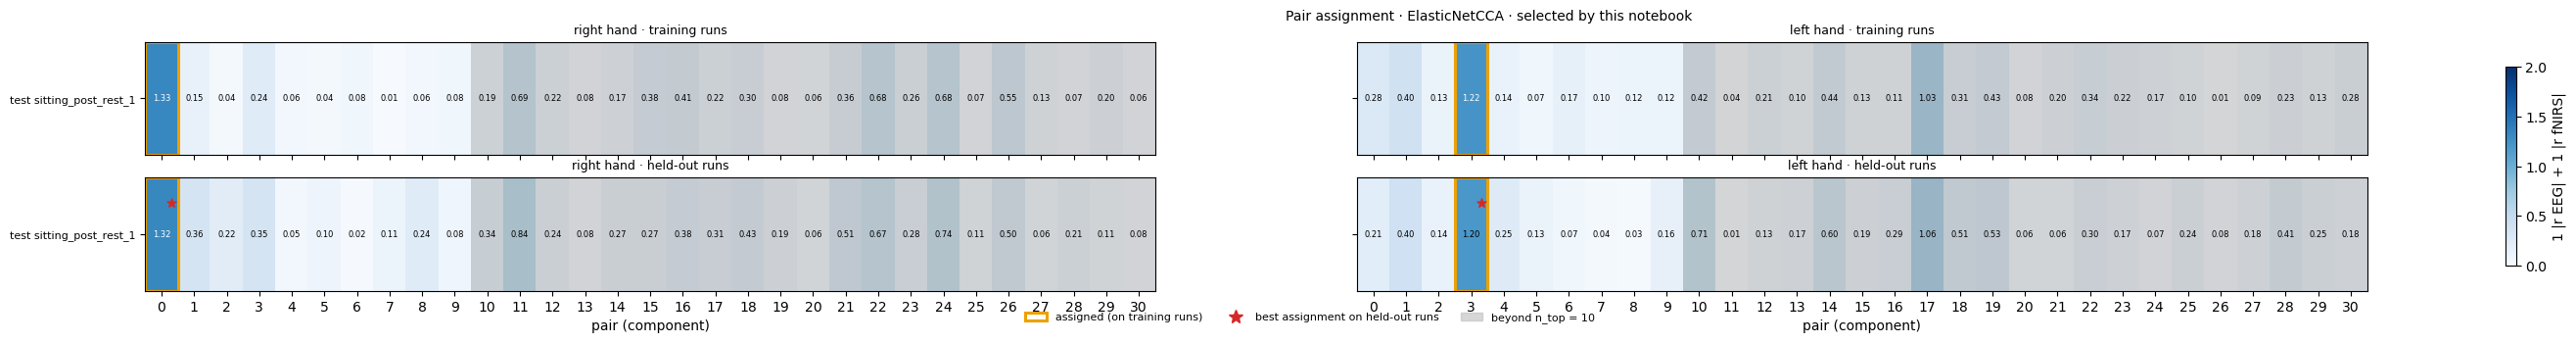

In [10]:
fig = plot_pair_assignment(selection, cfg.unmixing.assignment)
plt.show()

## 3. Choosing hyperparameters

The penalties above were not guessed: `select_and_score` chooses a method's
hyperparameters without ever looking at the test group. Here it does so for
**ElasticNetTCCA**, the temporal version of ElasticNetCCA. It also embeds the EEG
with copies delayed by `time_shifts` (seconds), so a pair can model the few seconds
by which the haemodynamic response trails the EEG; it finds the best shift per pair.

1. Each dev group is held out once as the **validation** group; every combination of
   the grid is fit on the other dev groups and scored on it.
2. Each **metric** (`unmixing.metrics`) averages a combination's scores over the
   folds; the best combination per metric wins.
3. The winner is refit on all dev groups and scored on the test group, as in step 2.

The grid comes from `configs/unmixing/grids.yaml`. The full ElasticNetTCCA grid has
1200 combinations; the tutorial experiment narrows it with `grid_overrides` to a few
around the values the full grid selects, to keep this fast.

In [11]:
selections, landscape, combinations = select_and_score(
    recordings, subject.test_group, "ElasticNetTCCA", cfg.unmixing, hands, logger=logger,
    trial_classes=subject.trial_classes)

table = pd.DataFrame([{**{k: str(v) for k, v in c.params.items()}, **c.means}
                      for c in combinations])
display(table[[*combinations[0].params, *cfg.unmixing.metrics]].round(3))

2026-11-09 08:39:19 [INFO] ElasticNetTCCA: grid search, 4 combinations x 4 folds (validation sitting_post_rest_2, sitting_pre_rest_1, sitting_pre_rest_2, sitting_pre_rest_3)


2026-11-09 08:39:23 [INFO] ElasticNetTCCA: grid search done in 4 s


,l1_reg,l2_reg,time_shifts,joint_avg,canonical_correlation_avg
0,"[0.2, 0.2]","[1.0, 1.2]",[0. 5.],0.623,0.258
1,"[0.2, 0.2]","[1.0, 1.2]",[0. 7.],0.624,0.226
2,"[0.2, 0.2]","[1.0, 1.5]",[0. 5.],0.621,0.256
3,"[0.2, 0.2]","[1.0, 1.5]",[0. 7.],0.626,0.225


`selection_report` is the summary the pipeline logs for each selected model: the
validation score and settings, then the test scores per hand.

In [12]:
for s in selections:
    print(selection_report(s))

ElasticNetTCCA by joint_avg: validation (dev) 0.626 with {'l1_reg': [0.2, 0.2], 'l2_reg': [1.0, 1.5], 'time_shifts': array([0., 7.])}
    test sitting_post_rest_1  right_hand pair  1  r eeg 0.53 fnirs 0.80  canonical r +0.29  pattern r eeg 0.80 fnirs 0.84  leak eeg 0.02 fnirs 0.33  (best pair 1)
    test sitting_post_rest_1  left_hand  pair  0  r eeg 0.37 fnirs 0.80  canonical r +0.22  pattern r eeg 0.77 fnirs 0.89  leak eeg 0.00 fnirs 0.20  (best pair 0)
    test sitting_post_rest_1  ISI eeg 0.04 fnirs 0.03
ElasticNetTCCA by canonical_correlation_avg: validation (dev) 0.258 with {'l1_reg': [0.2, 0.2], 'l2_reg': [1.0, 1.2], 'time_shifts': array([0., 5.])}
    test sitting_post_rest_1  right_hand pair  1  r eeg 0.50 fnirs 0.79  canonical r +0.31  pattern r eeg 0.80 fnirs 0.84  leak eeg 0.01 fnirs 0.34  (best pair 1)
    test sitting_post_rest_1  left_hand  pair  3  r eeg 0.45 fnirs 0.79  canonical r +0.26  pattern r eeg 0.75 fnirs 0.86  leak eeg 0.01 fnirs 0.20  (best pair 3)
    test s

## 4. The whole pipeline

`run` does everything from notebooks 01 to 04 for every method of the experiment,
classifies the trials (notebook 05), and writes the result to
`results/runs/<experiment>/<dataset>/<started>/`. It is exactly what
`python main.py --config ... --subject ...` runs.

In [13]:
result = run(cfg, subject, logger)

2026-11-09 08:39:24 [INFO] Experiment 'tutorial' on subject 'sub01' (synthetic, groups=['sitting_post_rest_1', 'sitting_post_rest_2', 'sitting_pre_rest_1', 'sitting_pre_rest_2', 'sitting_pre_rest_3'], test_group=sitting_post_rest_1)


2026-11-09 08:39:26 [INFO] Loaded 15 runs
  sitting_post_rest_1: run_001_seed_2792333187, run_002_seed_1570621782, run_003_seed_492650652
  sitting_post_rest_2: run_001_seed_2799647766, run_002_seed_1777453137, run_003_seed_730335040
  sitting_pre_rest_1: run_001_seed_2418716002, run_002_seed_1946698139, run_003_seed_2902985657
  sitting_pre_rest_2: run_001_seed_4057827324, run_002_seed_3300820366, run_003_seed_734525239
  sitting_pre_rest_3: run_001_seed_4154957764, run_002_seed_1717172445, run_003_seed_2053051004
  data: data/synthetic/sub01_snr_fnirs-5_eeg5
  background: data/background_recordings/sub01


2026-11-09 08:39:26 [WARNING] Pruning notches the EEG at 50, 100 Hz before bad-channel detection (eeg.line_freqs in the pruning YAML that the experiment's 'pruning:' names). It must match the mains frequency of the recording.


2026-11-09 08:39:33 [INFO] Pruning: EEG interpolated {'sub01_sitting_post_rest_1': ('CP1', 'F8', 'FC2', 'Fp2', 'T8'), 'sub01_sitting_post_rest_2': ('CP1', 'F8', 'FC2', 'Fp2', 'T8'), 'sub01_sitting_pre_rest_1': ('CP1', 'F8', 'Fp2', 'T8'), 'sub01_sitting_pre_rest_2': ('CP1', 'F8', 'FC2', 'Fp2'), 'sub01_sitting_pre_rest_3': ('CP1', 'F8', 'FC2', 'Fp2')}; fNIRS dropped 12 channels (bad per recording: {'sub01_sitting_pre_rest_1': 12})


2026-11-09 08:40:12 [INFO] Preprocessing: 15 runs, EEG feature 'bandpower'


2026-11-09 08:40:12 [INFO] sitting_post_rest_1/run_001_seed_2792333187: window 23.5-148.4 s · EEG 23.6-148.4 s (924) · fNIRS 23.6-148.4 s (924)


... (39 outputs left out)

2026-11-09 08:40:17 [INFO] ElasticNetTCCA by joint_avg: classification of test group sitting_post_rest_1, 104 training and 26 test trials (dropped 12 and 3)
    eeg_fnirs  accuracy 1.00  recall left 1.00  right 1.00
    eeg        accuracy 1.00  recall left 1.00  right 1.00
    fnirs      accuracy 0.96  recall left 0.92  right 1.00


2026-11-09 08:40:18 [INFO] ElasticNetTCCA by canonical_correlation_avg: classification of test group sitting_post_rest_1, 104 training and 26 test trials (dropped 12 and 3)
    eeg_fnirs  accuracy 0.96  recall left 0.92  right 1.00
    eeg        accuracy 1.00  recall left 1.00  right 1.00
    fnirs      accuracy 0.96  recall left 0.92  right 1.00


2026-11-09 08:40:18 [INFO] Results written to results/runs/tutorial/sub01_snr_fnirs-5_eeg5/2026-11-09T08-39-24/results


2026-11-09 08:41:04 [INFO] Figures written to results/runs/tutorial/sub01_snr_fnirs-5_eeg5/2026-11-09T08-39-24/figures


## Next

Notebook 05 reads this run back from disk and looks at its results and
classification.